In [1]:
import pandas as pd

inc = pd.read_csv("data/processed/incidents_clean.csv", dtype={"station": str})
stations_raw = pd.read_csv("data/raw/fire-station-locations - 4326.csv")
nbhd = pd.read_csv("data/raw/Neighbourhoods - 4326.csv")
runareas = pd.read_csv("data/raw/toronto-fire-services-run-areas - 4326.csv")

for name, d in [("incidents", inc), ("stations", stations_raw),
                ("neighbourhoods", nbhd), ("run areas", runareas)]:
    print(name, d.shape)

incidents (26168, 52)
stations (85, 18)
neighbourhoods (158, 12)
run areas (84, 21)


/var/folders/98/p89mc3nd1d34f9jndy3v2lz00000gn/T/ipykernel_33880/1239390480.py:3: DtypeWarning: Columns (5: Incident_Station_Area) have mixed types. Specify dtype option on import or set low_memory=False.
  inc = pd.read_csv("data/processed/incidents_clean.csv", dtype={"station": str})


In [2]:
print(stations_raw["TYPE_DESC"].value_counts())
stations_raw[["STATION", "ADDRESS", "TYPE_DESC"]].head()

TYPE_DESC
Fire Station    84
Ops Training     1
Name: count, dtype: int64


,STATION,ADDRESS,TYPE_DESC
0,211.0,900 Tapscott Rd,Fire Station
1,214.0,745 Meadowvale Rd,Fire Station
2,426.0,140 Lansdowne Ave,Fire Station
3,121.0,10 William Carson Cres,Fire Station
4,412.0,267 Humberline Dr,Fire Station


In [3]:
print(stations_raw.loc[stations_raw["TYPE_DESC"] != "Fire Station", ["ADDRESS", "STATION", "TYPE_DESC"]])
print(stations_raw["geometry"].iloc[0])

                ADDRESS  STATION     TYPE_DESC
36  25 Old Eglinton Ave      NaN  Ops Training
{"coordinates": [[-79.24287003538682, 43.82399272520154]], "type": "MultiPoint"}


In [4]:
stations = stations_raw[(stations_raw["TYPE_DESC"] == "Fire Station") & stations_raw["STATION"].notna()].copy()
stations["station"] = stations["STATION"].astype(int).astype(str)
print(len(stations), "fire stations")

84 fire stations


In [5]:
import json
print(nbhd["AREA_SHORT_CODE"].nunique(), "neighbourhoods")
print("shape type:", json.loads(nbhd["geometry"].iloc[0])["type"])
nbhd[["AREA_SHORT_CODE", "AREA_NAME"]].head()

158 neighbourhoods
shape type: MultiPolygon


,AREA_SHORT_CODE,AREA_NAME
0,174,South Eglinton-Davisville
1,173,North Toronto
2,172,Dovercourt Village
3,171,Junction-Wallace Emerson
4,170,Yonge-Bay Corridor


In [6]:
print(runareas["AREA_SHORT_CODE"].nunique(), "run areas")
runareas[["AREA_SHORT_CODE", "RUN_AREA"]].head()

84 run areas


,AREA_SHORT_CODE,RUN_AREA
0,114,114
1,111,111
2,112,112
3,143,143
4,235,235


In [7]:
inc_codes = set(inc["station"].dropna())
station_codes = set(stations["station"])
runarea_codes = set(runareas["AREA_SHORT_CODE"].astype(str))

print("distinct codes in incidents:", len(inc_codes))
print("stations:", len(station_codes), "| run areas:", len(runarea_codes))
print("stations and run areas identical:", station_codes == runarea_codes)
print("in incidents but not a station:", sorted(inc_codes - station_codes))
print("stations with no incidents:", sorted(station_codes - inc_codes))

distinct codes in incidents: 86
stations: 84 | run areas: 84
stations and run areas identical: True
in incidents but not a station: ['145P', '424']
stations with no incidents: []


In [8]:
unmatched = ~inc["station"].isin(station_codes)
print(unmatched.sum(), "incidents with no matching station")
inc.loc[unmatched, "station"].value_counts(dropna=False)

26 incidents with no matching station


station
424     23
NaN      2
145P     1
Name: count, dtype: int64

# Stage 3a summary: getting to know the other files

Before putting incidents on a map, I opened the other three files and checked that they fit together with the incident data.

The stations file has 85 rows, but one of them is a training site ("Ops Training") with no station number, so I dropped it and kept the 84 actual fire stations. The neighbourhoods file has 158 neighbourhoods, each stored as an outline made of one or more closed shapes (MultiPolygon). The run areas file has 84 areas, one per station.

The most useful check was on the codes. The 84 station numbers and the 84 run-area codes are exactly the same, and all 84 stations show up in the incident data, so I can trust the station code recorded on each incident. The incidents contain 86 distinct codes, though, and two of them don't belong to any station: 424 (23 incidents) and 145P (1 incident). Two more incidents have no code at all. In total, 26 of 26,168 incidents (about 0.1%) cannot be tied to a listed station by code. That is too small to matter much, but I will report it and handle those rows explicitly instead of hiding them.

**I dropped the training site** because it isn't somewhere trucks respond from, so keeping it would add a point that distorts the distances.  

**The matching codes matter** because it shows the station code on each incident really means "the station assigned to cover this area," so I can later compare the assigned station with simply the nearest one.

In [9]:
import json
import numpy as np
from matplotlib.path import Path

def polygons_of(geom_text):
    g = json.loads(geom_text)
    return g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]

shapes = [(str(r["AREA_SHORT_CODE"]), r["AREA_NAME"], polygons_of(r["geometry"]))
          for _, r in nbhd.iterrows()]
print(len(shapes), "neighbourhood shapes ready")

158 neighbourhood shapes ready


In [10]:
has = inc["has_coords"].to_numpy()
pts = inc.loc[has, ["Longitude", "Latitude"]].to_numpy()

code = np.full(len(pts), None, dtype=object)
name = np.full(len(pts), None, dtype=object)

for ncode, nname, polys in shapes:
    for poly in polys:
        inside = Path(poly[0]).contains_points(pts)   # inside the outer outline
        for hole in poly[1:]:
            inside &= ~Path(hole).contains_points(pts)  # but not inside a hole
        new = inside & (code == None)                   # only if not already assigned
        code[new], name[new] = ncode, nname

inc["neighbourhood_id"] = None
inc["neighbourhood_name"] = None
inc.loc[has, "neighbourhood_id"] = code
inc.loc[has, "neighbourhood_name"] = name

In [11]:
print("placed in a neighbourhood:", inc["neighbourhood_id"].notna().sum(), "of", len(inc))
print("had coordinates but fell outside every neighbourhood:", (has & inc["neighbourhood_id"].isna()).sum())

placed in a neighbourhood: 26092 of 26168
had coordinates but fell outside every neighbourhood: 74


In [12]:
per_nbhd = inc.groupby(["neighbourhood_id", "neighbourhood_name"]).size().sort_values()
print(len(per_nbhd), "neighbourhoods | smallest:", per_nbhd.iloc[0], "| median:", per_nbhd.median(), "| largest:", per_nbhd.iloc[-1])
per_nbhd.head(3)

158 neighbourhoods | smallest: 49 | median: 143.0 | largest: 770


neighbourhood_id  neighbourhood_name   
15                Kingsway South           49
140               Guildwood                52
49                Bayview Woods-Steeles    52
dtype: int64

In [13]:
stations["lon"] = [json.loads(g)["coordinates"][0][0] for g in stations["geometry"]]
stations["lat"] = [json.loads(g)["coordinates"][0][1] for g in stations["geometry"]]

LAT0, LON0 = 43.70, -79.40
def to_km(lat, lon):
    x = (np.asarray(lon) - LON0) * 111.32 * np.cos(np.radians(LAT0))
    y = (np.asarray(lat) - LAT0) * 110.57
    return np.column_stack([x, y])

stations[["station", "lat", "lon"]].head(3)

,station,lat,lon
0,211,43.823993,-79.242870
1,214,43.794211,-79.163602
2,426,43.645086,-79.438867


In [14]:
from scipy.spatial import cKDTree

tree = cKDTree(to_km(stations["lat"], stations["lon"]))
d, i = tree.query(to_km(inc.loc[has, "Latitude"], inc.loc[has, "Longitude"]))

inc["nearest_station"] = None
inc["dist_nearest_km"] = np.nan
inc.loc[has, "nearest_station"] = stations["station"].to_numpy()[i]
inc.loc[has, "dist_nearest_km"] = d
inc["dist_nearest_km"].describe().round(2)

count    26166.00
mean         1.03
std          0.55
min          0.03
25%          0.61
50%          0.96
75%          1.39
max          5.77
Name: dist_nearest_km, dtype: float64

In [15]:
xy = stations.set_index("station")[["lat", "lon"]].rename(columns={"lat": "st_lat", "lon": "st_lon"})
a = inc.join(xy, on="station")
ok = has & a["st_lat"].notna().to_numpy()

inc["dist_assigned_km"] = np.nan
inc.loc[ok, "dist_assigned_km"] = np.linalg.norm(
    to_km(inc.loc[ok, "Latitude"], inc.loc[ok, "Longitude"]) - to_km(a.loc[ok, "st_lat"], a.loc[ok, "st_lon"]), axis=1)

print("assigned station is also the nearest one:", round((inc["station"] == inc["nearest_station"])[ok].mean(), 3))
print("incidents more than 5 km from their assigned station:", (inc["dist_assigned_km"] > 5).sum())
inc["dist_assigned_km"].describe().round(2)

assigned station is also the nearest one: 0.823
incidents more than 5 km from their assigned station: 173


count    26140.00
mean         1.17
std          0.85
min          0.03
25%          0.63
50%          1.00
75%          1.53
max         38.80
Name: dist_assigned_km, dtype: float64

Matplotlib is building the font cache; this may take a moment.


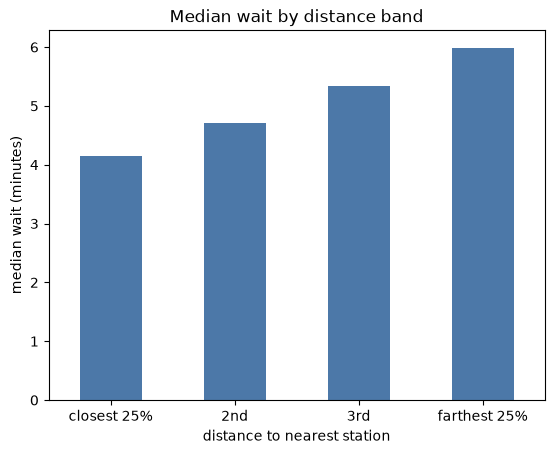

dist_band
closest 25%     4.15
2nd             4.72
3rd             5.33
farthest 25%    5.98
Name: wait_s, dtype: float64

In [16]:
import matplotlib.pyplot as plt

inc["dist_band"] = pd.qcut(inc["dist_nearest_km"], 4,
                           labels=["closest 25%", "2nd", "3rd", "farthest 25%"])
band = inc.groupby("dist_band", observed=True)["wait_s"].median() / 60

ax = band.plot(kind="bar", rot=0, color="#4C78A8")
ax.set_ylabel("median wait (minutes)")
ax.set_xlabel("distance to nearest station")
ax.set_title("Median wait by distance band")
plt.show()
band.round(2)

In [18]:
inc.to_csv("data/processed/incidents_geo.csv", index=False)
print("saved", len(inc), "rows")

saved 26168 rows


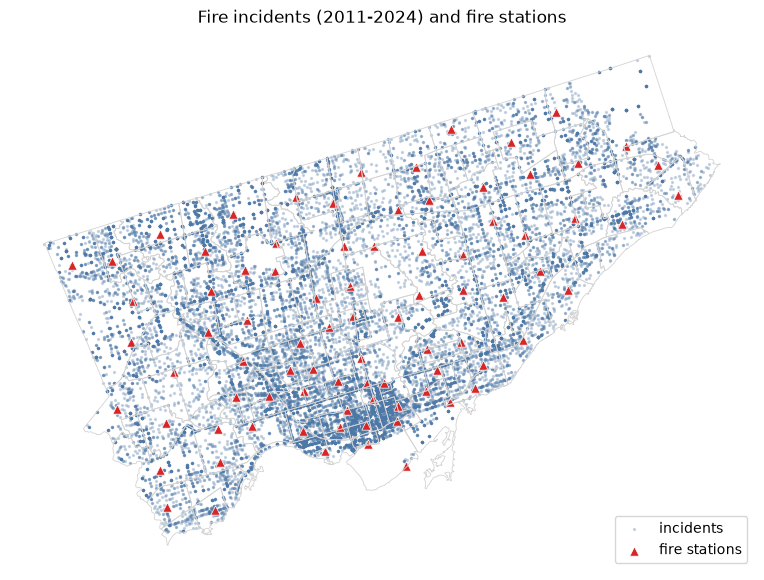

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 7))

for _, _, polys in shapes:                       # neighbourhood outlines
    for poly in polys:
        ring = np.array(poly[0])
        ax.plot(ring[:, 0], ring[:, 1], color="lightgrey", linewidth=0.6)

ok = inc["has_coords"]
ax.scatter(inc.loc[ok, "Longitude"], inc.loc[ok, "Latitude"],
           s=2, alpha=0.25, color="#4C78A8", label="incidents")
ax.scatter(stations["lon"], stations["lat"], s=45, marker="^", color="#D62728",
           edgecolor="white", linewidth=0.5, label="fire stations")

ax.set_aspect(1 / np.cos(np.radians(43.7)))
ax.set_axis_off()
ax.legend(loc="lower right")
ax.set_title("Fire incidents (2011-2024) and fire stations")
plt.show()

# Stage 3b summary: putting incidents on the map

With the files checked, I placed every incident inside a neighbourhood and measured how far it was from a fire station.

For the neighbourhoods, I tested each incident's coordinates against each neighbourhood outline, taking care to subtract the holes some outlines have. 26,092 of the 26,168 cleaned incidents landed inside one of the 158 neighbourhoods. Of the other 76, two have no usable coordinates, and 74 have coordinates but fall outside every outline, probably on boundary edges or just past the city limit. I left those unplaced instead of guessing. Neighbourhood sizes range from 49 to 770 incidents, with a median of 143, so none is too small to say anything about.

For distance, I converted latitude and longitude into a flat kilometre grid and found the nearest of the 84 stations for each incident. The median incident is 0.96 km from its nearest station, and the farthest is 5.8 km. I also measured the distance to the station recorded on each incident. That is the nearest station about 82% of the time, which is plausible near the edges of run areas. But 173 incidents are more than 5 km from their assigned station, and the largest gap is 38.8 km. Those are probably wrong coordinates or help from a distant station, so I'll test how much they matter when I check my results.

A first look at the pattern: when I split incidents into four equal groups by distance to the nearest station, the median wait rises steadily, from 4.15 minutes in the closest group to 4.72, 5.33 and 5.98 minutes in the farthest. That is about 1.8 minutes slower. It is only a description so far, because distance could be standing in for something else, such as time of day or the part of the city, and I'll separate those in the modelling stage.
## Some Important Points
**I converted to kilometres first** because a degree of longitude covers less ground than a degree of latitude at Toronto's latitude, so measuring in degrees would distort distances. A flat kilometre grid makes straight-line distance mean what it should.  

**I leave the 74 unplaced incidents out** because putting them in a neighbourhood would be a guess, and 74 of 26,168 is too few to change anything.